# Assignment 3 — Module 3: Evolutionary and Swarm Optimization

**Student Name:** Arendra Singh Rajput  
**Roll No.:** 2023BTCSE003  
**Enrollment No.:** JLU08391  
**Course:** B.Tech CSE, 4th Year  
**Subject:** Soft Computing Exercise  

---

## Practical 5: Mutation Operations for Introducing Variation

### Aim
To implement the mutation operation for introducing variations in individuals using Python.

### Theory
**Mutation** makes small random changes to an individual. It maintains diversity and lets the GA escape local optima. Mutation is applied with a small probability $p_m$ (typically $1/L$ for $L$ genes in binary GAs).

- **Bit-flip mutation (binary):** each bit flips with probability $p_m$.
- **Gaussian mutation (real-valued):** $x_i' = x_i + \mathcal{N}(0,\sigma^2)$, clipped to the bounds.
- **Swap mutation (permutation):** two positions are chosen and their items exchanged.

### Mutation operators

In [1]:
import numpy as np
import matplotlib.pyplot as plt

gen_rng = np.random.default_rng(3)

def bit_flip_mutation(ind, pm):
    flip = gen_rng.random(len(ind)) < pm            # True where a bit should flip
    out = ind.copy()
    out[flip] = 1 - out[flip]
    return out

def gaussian_mutation(ind, pm, sigma, low, high):
    mask = gen_rng.random(len(ind)) < pm
    out = ind.copy()
    out[mask] += gen_rng.normal(0, sigma, size=mask.sum())
    return np.clip(out, low, high)              # keep genes inside bounds

def swap_mutation(perm):
    out = perm.copy()
    i, j = gen_rng.choice(len(perm), size=2, replace=False)
    out[i], out[j] = out[j], out[i]
    return out

### Demonstrating each mutation

In [2]:
b = np.array([1, 0, 1, 1, 0, 0, 1, 0])
print("Binary      before:", b)
print("Binary      after :", bit_flip_mutation(b, pm=0.25))

r = np.array([1.0, -2.0, 0.5])
print("Real-valued before:", r)
print("Real-valued after :", np.round(gaussian_mutation(r, pm=0.5, sigma=0.3, low=-5.12, high=5.12), 3))

p = np.array([0, 1, 2, 3, 4])
print("Permutation before:", p)
print("Permutation after :", swap_mutation(p))

Binary      before: [1 0 1 1 0 0 1 0]
Binary      after : [0 1 1 1 1 0 1 1]
Real-valued before: [ 1.  -2.   0.5]
Real-valued after : [ 1.    -2.106  0.416]
Permutation before: [0 1 2 3 4]
Permutation after : [0 1 4 3 2]


### Effect of mutation rate on diversity

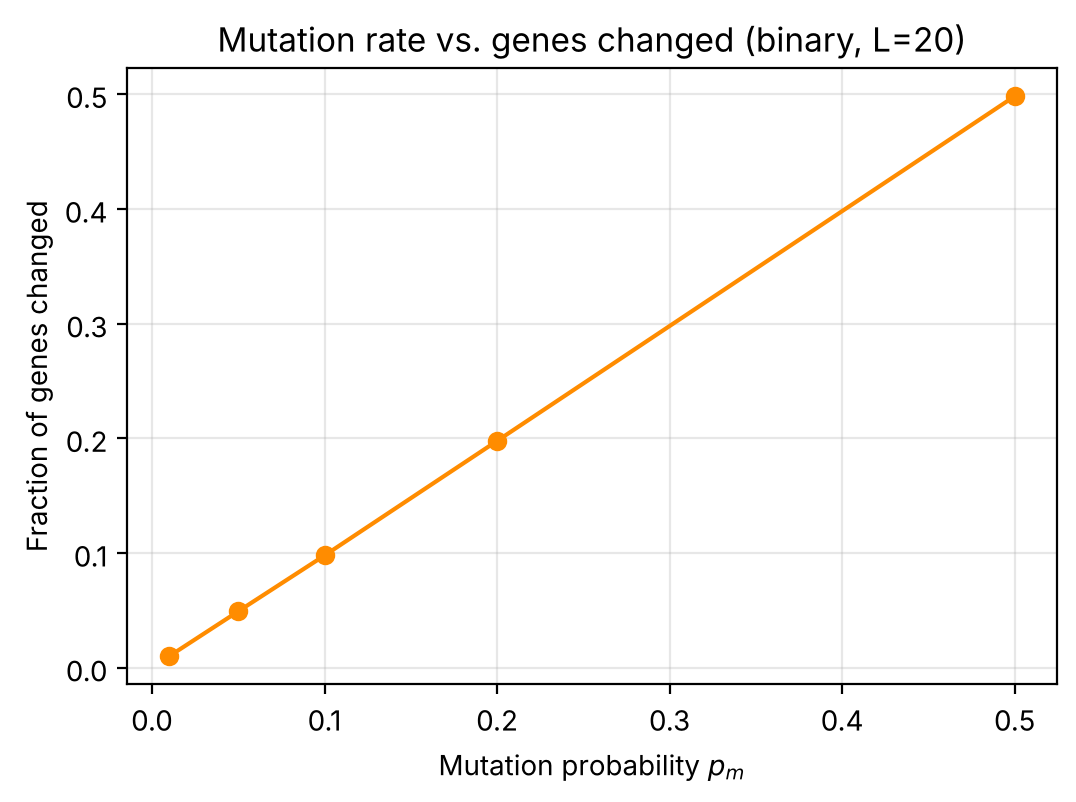

p_m = 0.01 -> 0.010 of genes changed
p_m = 0.05 -> 0.049 of genes changed
p_m = 0.10 -> 0.098 of genes changed
p_m = 0.20 -> 0.198 of genes changed
p_m = 0.50 -> 0.498 of genes changed


In [3]:
# Measure the average fraction of genes changed for several mutation rates
rates = [0.01, 0.05, 0.1, 0.2, 0.5]
changed_frac = []
for pm in rates:
    total_changed = 0
    for _ in range(2000):
        ind = gen_rng.integers(0, 2, 20)
        total_changed += np.sum(bit_flip_mutation(ind, pm) != ind)
    changed_frac.append(total_changed / (2000 * 20))

plt.figure(figsize=(6, 4))
plt.plot(rates, changed_frac, 'o-', color='darkorange')
plt.xlabel('Mutation probability $p_m$'); plt.ylabel('Fraction of genes changed')
plt.title('Mutation rate vs. genes changed (binary, L=20)')
plt.grid(True, alpha=0.3); plt.show()
for pm, c in zip(rates, changed_frac):
    print(f"p_m = {pm:4.2f} -> {c:.3f} of genes changed")

### Observation
- Bit-flip mutation changes roughly a fraction $p_m$ of genes, which the rate experiment confirms.
- Gaussian mutation shifts real-valued genes by a small random amount and clips them inside the bounds.
- Swap mutation keeps the permutation valid, since it only exchanges two items.

### Conclusion
Implemented bit-flip, Gaussian and swap mutation, and showed that the mutation probability controls how much of the chromosome changes.